# Лабораторная работа №1: Регрессия.
## Часть 1. Знакомство с данными.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set(style="darkgrid")

В предоставленном датасете дано две таблицы - для красных и для белых вин. Объединим их вместе, при этом добавим новый признак, который будет указывать на тип вина - is_red, где значение 1 будет указывать на красное вино, 0 - на белое.


In [ ]:
red_wine = pd.read_csv('winequality-red.csv', sep=';')
white_wine = pd.read_csv('winequality-white.csv', sep=';')

red_wine['is_red'] = 1
white_wine['is_red'] = 0

data = pd.concat([red_wine, white_wine], ignore_index=True)

display(data.sample(5))

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
4187,6.8,0.18,0.30,12.8,0.062,19.0,171.0,0.99808,3.00,0.52,9.0,7,0
37,8.1,0.38,0.28,2.1,0.066,13.0,30.0,0.99680,3.23,0.73,9.7,7,1
726,8.1,0.72,0.09,2.8,0.084,18.0,49.0,0.99940,3.43,0.72,11.1,6,1
2024,7.0,0.21,0.28,8.7,0.045,37.0,222.0,0.99540,3.25,0.54,10.4,6,0
355,6.7,0.75,0.01,2.4,0.078,17.0,32.0,0.99550,3.55,0.61,12.8,6,1


In [ ]:
data.shape

(6497, 13)

In [ ]:
data.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality', 'is_red'],
      dtype='object')

Все признаки являются числовыми. Посмотрим на значения целевой переменной.

In [ ]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=["quality"])
y = data["quality"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

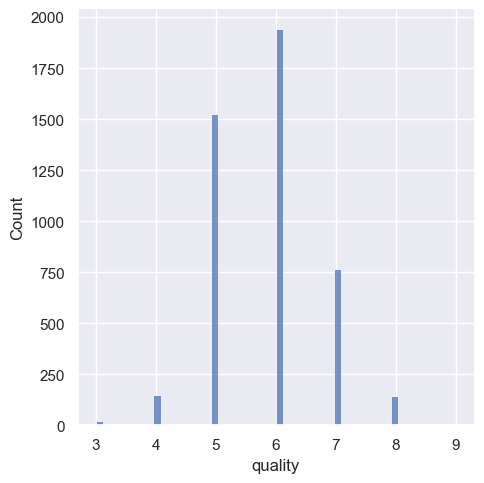

In [ ]:
sns.displot(y_train, stat='count')

Соотношение обучающей и тестовой выборок: 70% обучающих данных, 30% тестовых. Такая пропорция является оптимальным компромиссом. С одной стороны, мы оставляем алгоритмам достаточно большой объем данных, чтобы они могли выявить сложные внутренние закономерности химического состава вина. С другой стороны, 30% данных вполне достаточно, чтобы получить статистически значимую и надежную оценку того, как модель обобщает информацию на новых объектах.\
Если мы будем обучать множество моделей, перебирать их гиперпараметры и каждый раз проверять качество на одной и той же тестовой выборке, выбирая лучший результат, произойдет утечка данных или переобучение под тест. В итоге тестовая выборка начнет играть роль валидационной: мы неявно оптимизируем модель именно под эти конкретные 30% данных. Финальная метрика окажется завышенной и не будет отражать реальную ошибку алгоритма на абсолютно новых данных.

Судя по гистограмме, все данные распределены в одном диапазоне. Наличие аномальных примеров, которые могут негативно повлиять на обучение, не выявлено. 


Теперь стоит посмотреть на посмотреть на коэффициент корреляции Пирсона между признаками и целевой переменной, чтобы найти признаки, наиболее линейно связанные с целевой переменной.

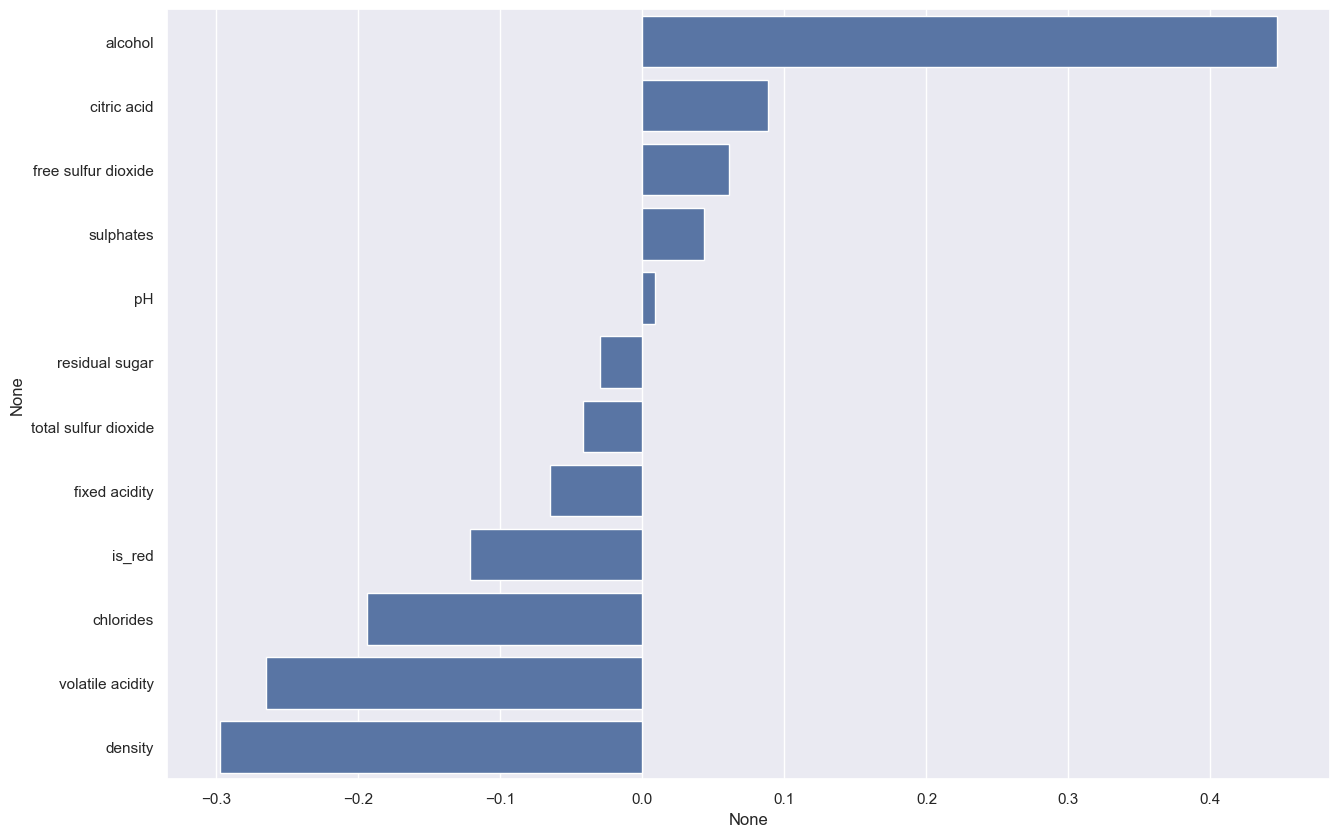

In [ ]:
numeric_data = X_train.select_dtypes([np.number])
numeric_data_mean = numeric_data.mean()
numeric_features = numeric_data.columns

X_train = X_train.fillna(numeric_data_mean)
X_test = X_test.fillna(numeric_data_mean)

correlations = X_train[numeric_features].corrwith(y_train).sort_values(ascending=False)

plot = sns.barplot(y=correlations.index, x=correlations)
plot.figure.set_size_inches(15, 10)

Посмотрим на признаки с самой сильной корреляцией(alcohol, volatile acidity, density) и построим усиковые диаграммы, чтобы проверить линейную зависимость этих признаков.

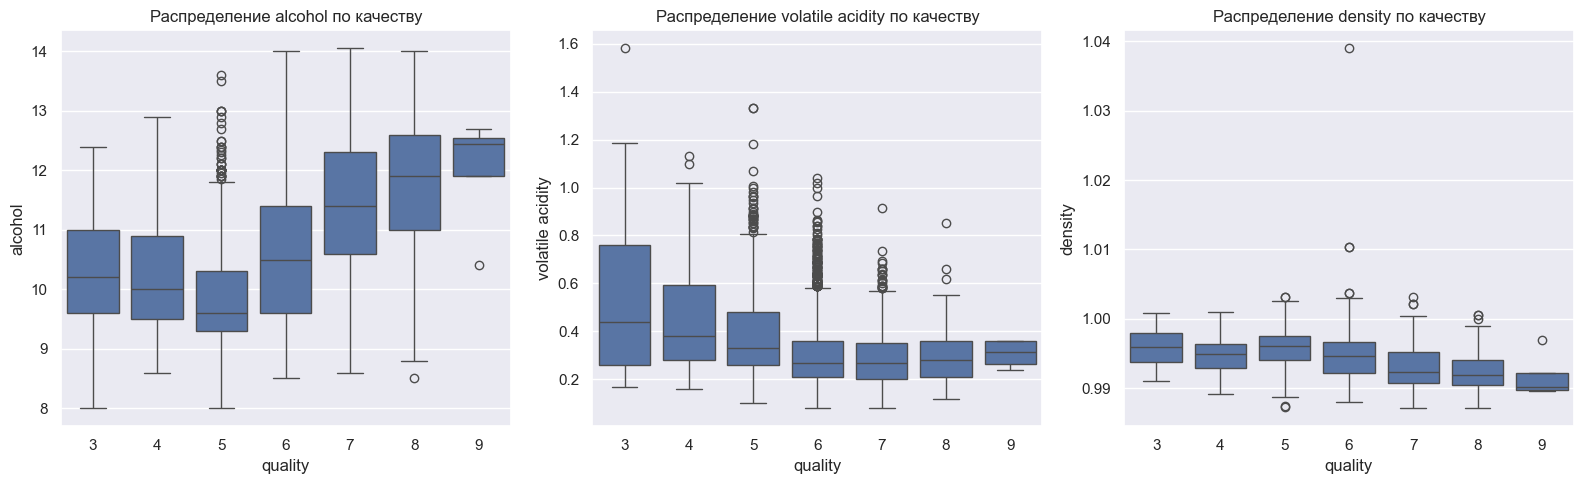

In [ ]:
fig, axs = plt.subplots(figsize=(16, 5), ncols=3)
features = ["alcohol", "volatile acidity", "density"]
for i, feature in enumerate(features):
    sns.boxplot(x=y_train, y=X_train[feature], ax=axs[i])
    axs[i].set_xlabel("quality")
    axs[i].set_ylabel(feature)
    axs[i].set_title(f"Распределение {feature} по качеству")

plt.tight_layout()
plt.show()

Из построенных диаграмм видно, что строгая линейная зависимость не подтверждается ни для одного из признаков. В контексте задачи это означает, что определить хорошее вино по одному или нескольким признакам невозможно, ведь хорошее вино - это удачный микс всех химических компонентов. Признаки с самой высокой корреляцией - спирт, плотность и летучая кислотность - могут по разному влиять на итоговую оценку вина в зависимости от набора других признаков.

## Часть 2. Baseline.

In [ ]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

baseline_prediction = y_train.mean()

y_pred_baseline = np.full(shape=y_test.shape, fill_value=baseline_prediction)

rmse_baseline = root_mean_squared_error(y_test, y_pred_baseline)
mae_baseline = mean_absolute_error(y_test, y_pred_baseline)

print(f"Baseline RMSE: {rmse_baseline}")
print(f"Baseline MAE:  {mae_baseline}")

Baseline RMSE: 0.8542089594834528
Baseline MAE:  0.6647089938138981


**Результаты Baseline**\
Для построения Baseline использовалось предсказание одной константой для всех объектов. Такой константой было выбрано среднее арифметическое целевой переменной.\
Полученные значения:
-   **Baseline RMSE:** ~0.8596
-   **Baseline MAE:** ~0.6691

- Что показывает MAE? Среднюю абсолютную ошибку по модулю. Она показывает, на сколько баллов в среднем ошибается модель (все ошибки учитываются пропорционально их размеру).\
- Что показывает RMSE? Корень из среднеквадратичной ошибки. Тоже показывает средний промах, но при этом сильно «штрафует» модель за крупные отклонения.
- Почему RMSE сильнее реагирует на большие ошибки? Из-за возведения ошибки в квадрат перед усреднением.
- Почему значения MAE и RMSE могут различаться? Когда RMSE заметно больше MAE, это означает наличие выбросов. Модель в среднем предсказывает хорошо (низкий MAE), но на единичных объектах (например, на редких винах с качеством 3 или 9) сильно ошибается, что резко завышает RMSE.

## Часть 3. Модели.

**Линейная регрессия**

Linear Regression RMSE: 0.7263871748775005
Linear Regression MAE:  0.5620633496709895


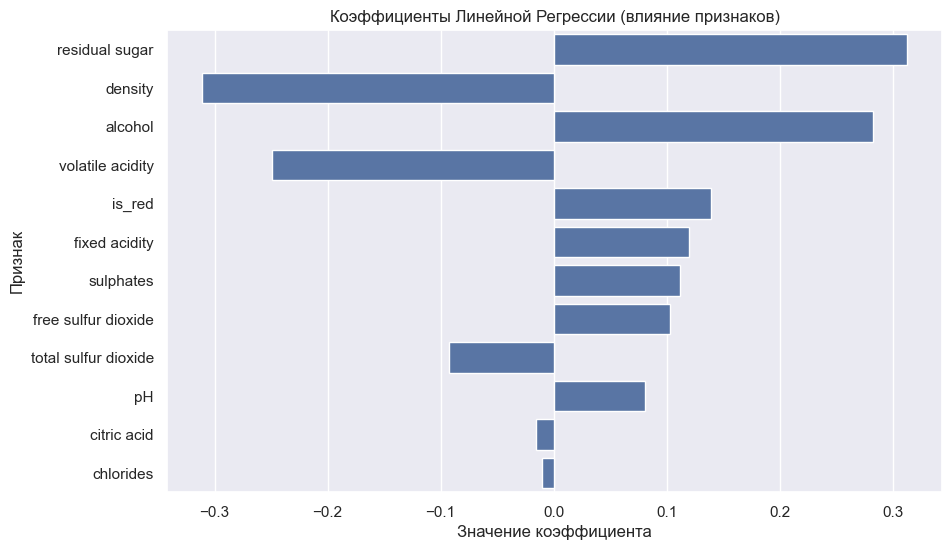

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import root_mean_squared_error, mean_absolute_error 

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)

rmse_lr = root_mean_squared_error(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)

print(f"Linear Regression RMSE: {rmse_lr}")
print(f"Linear Regression MAE:  {mae_lr}")

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr_model.coef_
})

coefficients['Abs_Coefficient'] = coefficients['Coefficient'].abs()
coefficients = coefficients.sort_values(by='Abs_Coefficient', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Coefficient', y='Feature', data=coefficients)
plt.title('Коэффициенты Линейной Регрессии (влияние признаков)')
plt.xlabel('Значение коэффициента')
plt.ylabel('Признак')
plt.show()

Масштабирование данных строго необходимо. В нашем датасете признаки имеют разные единицы измерения и измеряются в разных масштабах. Если не масштабировать данные, модель попытается сама скоменсировать эту разницу, выдав низкие коэффициенты признакам с высокими значениями и высокие коэффициенты признкам с маленькими значениями. Это повлечет за собой невозможность сравнивания признаков друг с другом.

**Случайный лес**

Random Forest RMSE: 0.6053
Random Forest MAE:  0.4380



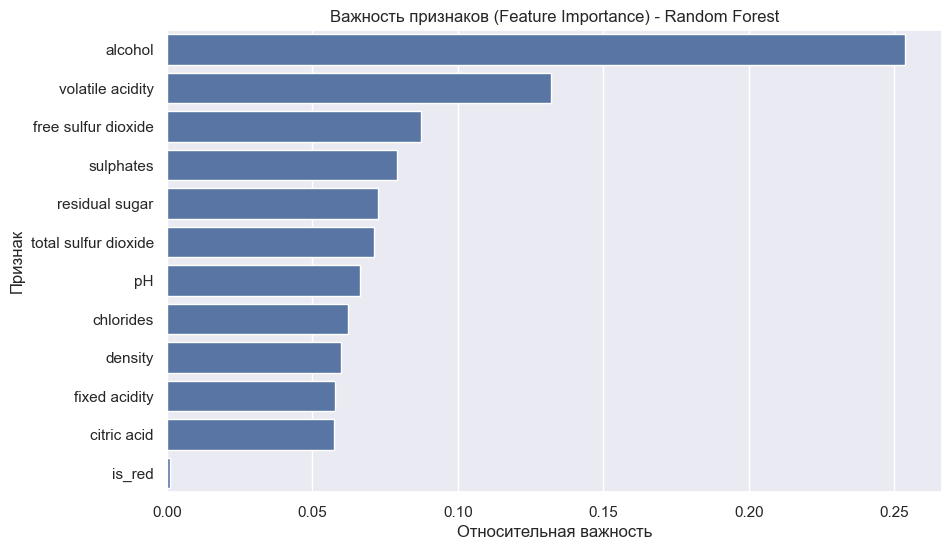

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

rmse_rf = root_mean_squared_error(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)

print(f"Random Forest RMSE: {rmse_rf:.4f}")
print(f"Random Forest MAE:  {mae_rf:.4f}\n")

feature_importances_rf = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importances_rf = feature_importances_rf.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importances_rf)
plt.title('Важность признаков (Feature Importance) - Random Forest')
plt.xlabel('Относительная важность')
plt.ylabel('Признак')
plt.show()

**Градиентный бустинг**

Gradient Boosting RMSE: 0.6721059794776836
Gradient Boosting MAE:  0.5298654443669152



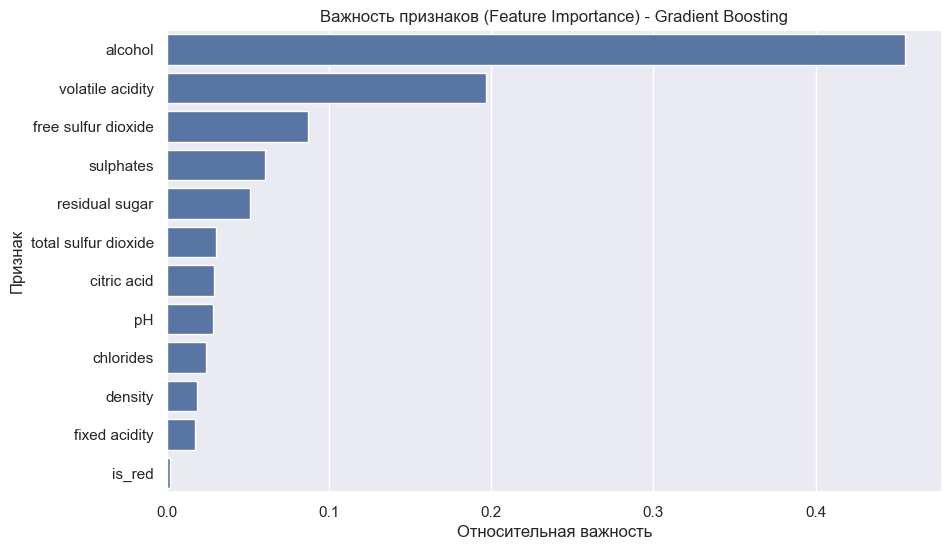

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(n_estimators=100, random_state=42)
gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)

rmse_gb = root_mean_squared_error(y_test, y_pred_gb)
mae_gb = mean_absolute_error(y_test, y_pred_gb)

print(f"Gradient Boosting RMSE: {rmse_gb}")
print(f"Gradient Boosting MAE:  {mae_gb}\n")

feature_importances_gb = pd.DataFrame({
    'Feature': X.columns,
    'Importance': gb_model.feature_importances_
})
feature_importances_gb = feature_importances_gb.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importances_gb)
plt.title('Важность признаков (Feature Importance) - Gradient Boosting')
plt.xlabel('Относительная важность')
plt.ylabel('Признак')
plt.show()

In [ ]:
results = pd.DataFrame({
    'Модель': ['Baseline', 'Linear Regression', 'Random Forest', 'Gradient Boosting'],
    'RMSE': [rmse_baseline, rmse_lr, rmse_rf, rmse_gb],
    'MAE': [mae_baseline, mae_lr, mae_rf, mae_gb]
})

results.set_index('Модель', inplace=True)
display(results.round(4))

,RMSE,MAE
Модель,,
Baseline,0.8542,0.6647
Linear Regression,0.7264,0.5621
Random Forest,0.6053,0.4380
Gradient Boosting,0.6721,0.5299


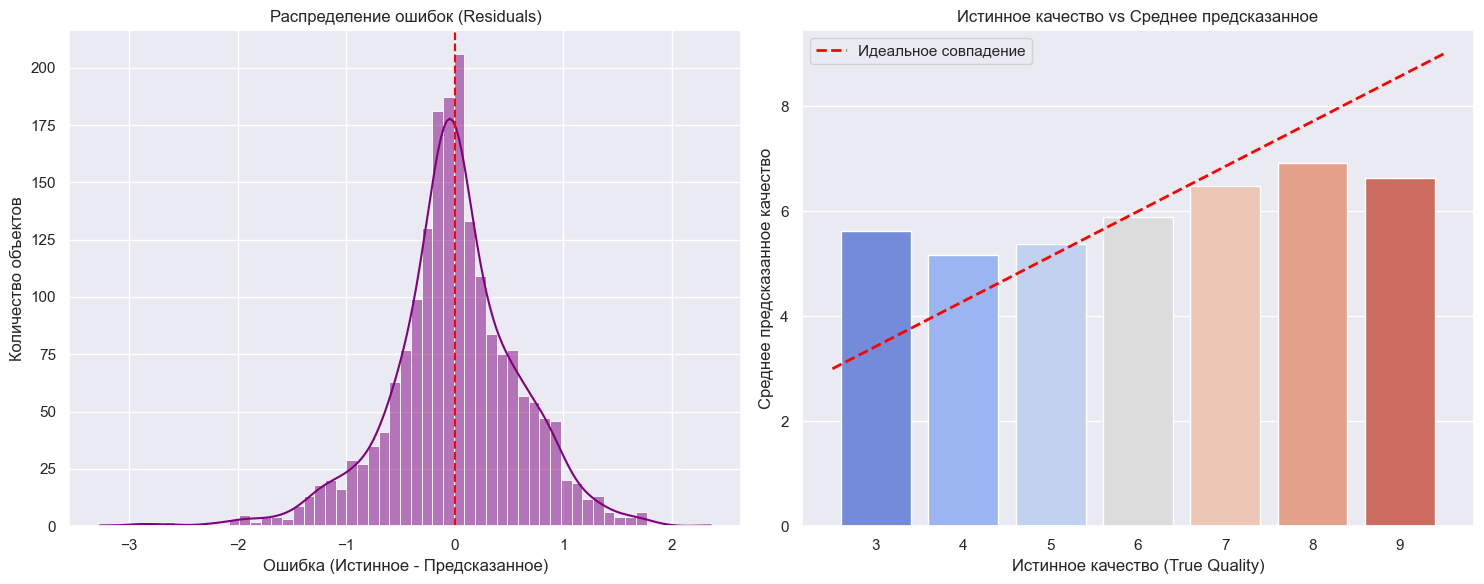

ТОП-5 объектов с наибольшей ошибкой предсказания:


,True_Quality,Predicted_Quality,Abs_Error,alcohol,volatile acidity,is_red
2339,3,6.27,3.27,12.6,0.39,0
4906,3,5.95,2.95,11.0,0.24,0
6344,3,5.86,2.86,10.5,0.26,0
4686,3,5.86,2.86,10.1,0.20,0
3016,3,5.63,2.63,11.0,0.55,0


In [ ]:
error_analysis = pd.DataFrame({
    'True_Quality': y_test,
    'Predicted_Quality': y_pred_rf
})

error_analysis['Error'] = error_analysis['True_Quality'] - error_analysis['Predicted_Quality']
error_analysis['Abs_Error'] = error_analysis['Error'].abs()

fig, axs = plt.subplots(figsize=(15, 6), ncols=2)

sns.histplot(error_analysis['Error'], kde=True, ax=axs[0], color='purple')
axs[0].set_title('Распределение ошибок (Residuals)')
axs[0].set_xlabel('Ошибка (Истинное - Предсказанное)')
axs[0].set_ylabel('Количество объектов')
axs[0].axvline(0, color='red', linestyle='--')

mean_predictions = error_analysis.groupby('True_Quality')['Predicted_Quality'].mean().reset_index()
sns.barplot(x='True_Quality', y='Predicted_Quality', data=mean_predictions, ax=axs[1], palette='coolwarm')
axs[1].plot([-0.5, len(mean_predictions)-0.5], [mean_predictions['True_Quality'].min(), mean_predictions['True_Quality'].max()], color='red', linestyle='--', linewidth=2, label='Идеальное совпадение')
axs[1].set_title('Истинное качество vs Среднее предсказанное')
axs[1].set_xlabel('Истинное качество (True Quality)')
axs[1].set_ylabel('Среднее предсказанное качество')
axs[1].legend()

plt.tight_layout()
plt.show()

print("ТОП-5 объектов с наибольшей ошибкой предсказания:")
worst_predictions = error_analysis.sort_values(by='Abs_Error', ascending=False).head(5)
worst_objects = X_test.loc[worst_predictions.index].copy()
worst_objects['True_Quality'] = worst_predictions['True_Quality']
worst_objects['Predicted_Quality'] = worst_predictions['Predicted_Quality'].round(2)
worst_objects['Abs_Error'] = worst_predictions['Abs_Error'].round(2)

display(worst_objects[['True_Quality', 'Predicted_Quality', 'Abs_Error', 'alcohol', 'volatile acidity', 'is_red']])

## Анализ ошибок (Random Forest)

**1. Распределение ошибок:**
Распределение ошибок на левом графике близко к нормальному и центрировано около нуля. Это значит, что модель не имеет сильного системного смещения в одну сторону.

**2. Качество предсказания для разных значений Quality:**
На правом графике отчетливо видна проблема предсказания редких классов:
* Для вин со средним качеством (`5` и `6`) среднее предсказание модели практически идеально совпадает с истинным значением (столбики касаются красной линии `y=x`).
* Однако на концах распределения модель сильно ошибается. Для редких очень плохих вин (качество `3`) модель стабильно завышает оценку, а для редких элитных вин (качество `8` или `9`) — стабильно занижает её.
* Эта проблема напрямую связана с сильным дисбалансом классов в нашем датасете. Подавляющее большинство объектов в обучающей выборке — это вина с оценкой 5 и 6. Модель случайного леса, стремясь минимизировать среднеквадратичную ошибку (RMSE) на всей выборке, становится консервативной. Встречая вино с нетипичными характеристиками, модель усредняет прогноз, подтягивая его к самому частотному классу (5-6).

**3. Анализ самых крупных ошибок:**
В таблице приведены ТОП-5 объектов, на которых модель ошиблась сильнее всего. В большинстве случаев мы видим, что модель столкнулась с редким вином (например, истинное качество 3 или 8), но химические признаки (`alcohol`, `volatile acidity`) у этого вина были нетипичными для его класса. 
Например, вино могло иметь высокий градус алкоголя (что обычно признак хорошего вина), но дегустаторы поставили ему низкую оценку из-за дисбаланса вкуса, который химический анализ уловить не смог. Модель, ориентируясь на высокий алкоголь, логично предсказала высокую оценку, что привело к большой абсолютной ошибке (Abs_Error).